# Bank Customer Churn Prediction with Logistic Regression and Decision Tree

In this project, a bank customer dataset from Kaggle is used to predict whether a customer will leave the bank, which is known as churn. Retaining existing customers is less costly than acquiring new ones, so predictive models can help banks plan their retention approach and target their resources. The dataset contains demographic and account information for 10,000 customers, and the target variable Exited indicates whether a customer left (1) or stayed (0). This makes it a supervised binary classification problem. Logistic Regression and Decision Tree algorithms are applied and compared.

## 1. Data Loading and Exploration

The bank customer churn dataset is loaded from a CSV file and the structure of the data is examined. The number of rows, columns, data types and summary statistics are checked to understand the dataset before analysis.

In [1]:
# Import libraries for data analysis, visualisation, and machine learning

# Pandas for data manipulation and NumPy for numerical operations
import pandas as pd
import numpy as np

# Seaborn and matplotlib for data visualisation
import seaborn as sns
from matplotlib import pyplot as plt

# Scikit-learn libraries for model training, evaluation, and preprocessing
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
from sklearn.feature_selection import SelectKBest, chi2, mutual_info_classif, f_classif
from sklearn.ensemble import ExtraTreesClassifier

# Display plots inline in the notebook
%matplotlib inline

In [2]:
# Load the bank customer churn dataset from csv file
df = pd.read_csv('Churn_Modelling.csv')

In [3]:
# List all column names to understand the structure of the dataset
df.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='object')

In [4]:
# Check the number of rows and columns in the dataset
df.shape

(10000, 14)

In [5]:
# Display the first five rows of the dataset
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [6]:
# Summary statistics for numerical columns to understand data distributions
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [7]:
# Display data types, non-null counts and memory usage
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


### Check data quality

* Missing values and duplicated rows are checked to identify any data quality issues before analysis.
* This dataset contains 10,000 rows and 14 columns covering customer demographics, account information and churn status.

In [8]:
# Check for missing values in each column
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [9]:
# Check for duplicated rows
print('Number of duplicated rows: {}'.format(df.duplicated().sum()))

Number of duplicated rows: 0


RowNumber is just a row index, CustomerId is a unique number assigned to each customer, and Surname is a personal name. None of these carry any information about whether a customer will churn or not. CustomerId has 10,000 unique values, one for each row, which confirms it is just an identifier. Since these three columns would only add noise to the model, they are all dropped before analysis.

In [10]:
# Drop RowNumber, CustomerId and Surname as they have no predictive value for churn prediction
print('RowNumber, CustomerId, Surname have no analytic value: {} different CustomerIds ... so we can drop them'
      .format(len(df['CustomerId'].unique())))
df = df.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1)

RowNumber, CustomerId, Surname have no analytic value: 10000 different CustomerIds ... so we can drop them


## 2. Exploratory Data Analysis
The target variable and the categorical and numerical features are analysed to understand patterns in the data. This helps to identify which features might be useful for predicting customer churn.

In [11]:
# Save a backup copy before exploratory analysis
df_original = df.copy()

In [12]:
# Check Exited variable distribution to see the balance between churned and stayed customers
print('Values and counts for Exited are:\n{}'.format(df['Exited'].value_counts()))
print('Values and normalised counts for Exited are:\n{}'.format(df['Exited'].value_counts(normalize=True)))

Values and counts for Exited are:
Exited
0    7963
1    2037
Name: count, dtype: int64
Values and normalised counts for Exited are:
Exited
0    0.7963
1    0.2037
Name: proportion, dtype: float64


* The target variable Exited is imbalanced with 79.6% class 0 (stayed) and 20.4% class 1 (churned), which is important to keep in mind when interpreting accuracy metrics.
* A model that always predicts 0 would achieve 79.6% accuracy, so F1 score, precision and recall are also examined.

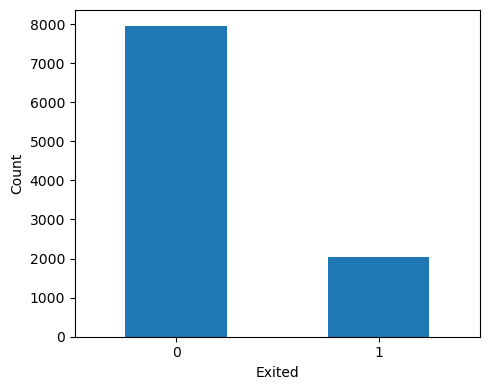

In [13]:
# Plot target variable distribution as a bar chart to visualise class distribution
df['Exited'].value_counts().plot.bar(figsize=(5, 4))
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Churn rate by Geography and Gender

Crosstab is used to examine whether Geography and Gender show different churn rates. If churn rates differ across categories, these features are likely to be useful for prediction.

Counts for Geography vs Exited are:
Exited        0    1
Geography           
France     4204  810
Germany    1695  814
Spain      2064  413

Normalised counts for Geography vs Exited are:
Exited            0         1
Geography                    
France     0.838452  0.161548
Germany    0.675568  0.324432
Spain      0.833266  0.166734

Counts for Gender vs Exited are:
Exited     0     1
Gender            
Female  3404  1139
Male    4559   898

Normalised counts for Gender vs Exited are:
Exited         0         1
Gender                    
Female  0.749285  0.250715
Male    0.835441  0.164559


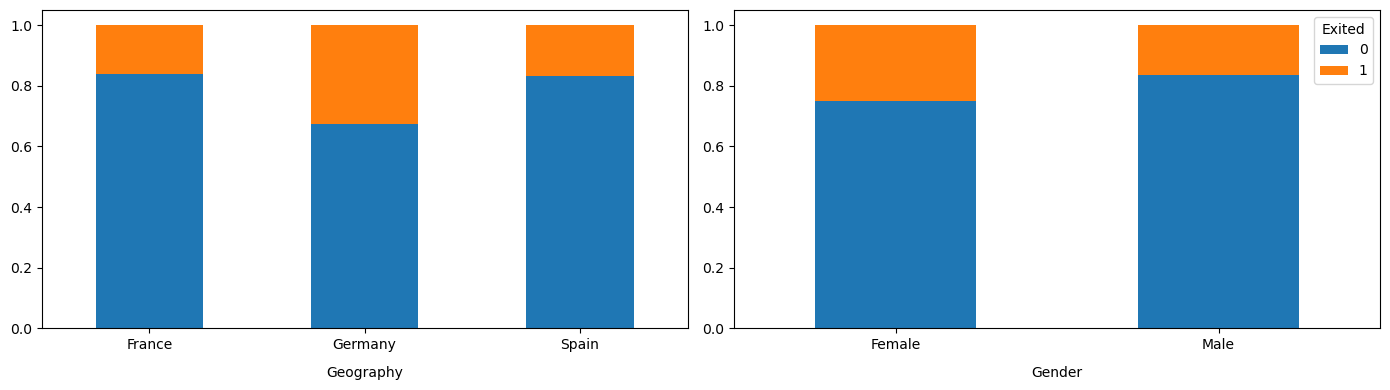

In [14]:
# Crosstab of Geography and Gender vs Exited to check if churn rates differ across categories
Geography = pd.crosstab(df['Geography'], df['Exited'])
print('Counts for Geography vs Exited are:\n{}'.format(Geography))

# Normalise Geography vs Exited
Geography = Geography.div(Geography.sum(1).astype(float), axis=0)
print('\nNormalised counts for Geography vs Exited are:\n{}'.format(Geography))

# Crosstab of Gender vs Exited to check if churn rates differ between male and female customers
Gender = pd.crosstab(df['Gender'], df['Exited'])
print('\nCounts for Gender vs Exited are:\n{}'.format(Gender))

# Normalise Gender vs Exited
Gender = Gender.div(Gender.sum(1).astype(float), axis=0)
print('\nNormalised counts for Gender vs Exited are:\n{}'.format(Gender))

# Plot normalised distributions as stacked bar charts
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 4))
Geography.plot(kind="bar", stacked=True, ax=axes[0], legend=False)
Gender.plot(kind="bar", stacked=True, ax=axes[1])
axes[0].tick_params(axis='x', rotation=0)
axes[1].tick_params(axis='x', rotation=0)
axes[0].set_xlabel('Geography', labelpad=10)
axes[1].set_xlabel('Gender', labelpad=10)
plt.tight_layout()
plt.show()


### Distributions of numerical variables

Histograms, density plots and boxplots are used to examine the shape, spread and any outliers of Age and Balance. These plots help check whether the data is skewed or has outliers that might need handling before modelling.

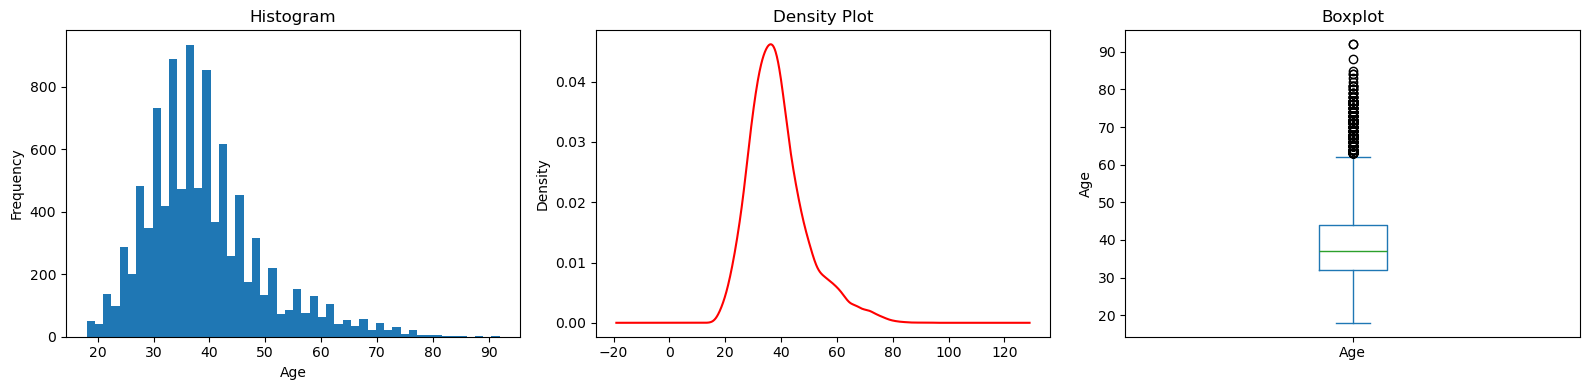

In [15]:
# Plot histogram, density and boxplot for Age variable
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))
df['Age'].plot(kind='hist', bins=50, ax=axes[0], xlabel="Age", title="Histogram")
df['Age'].plot(kind='density', color='r', ax=axes[1], xlabel="Age", title='Density Plot')
df['Age'].plot(kind='box', ax=axes[2], ylabel='Age', xlabel='', title='Boxplot')
plt.tight_layout()
plt.show()

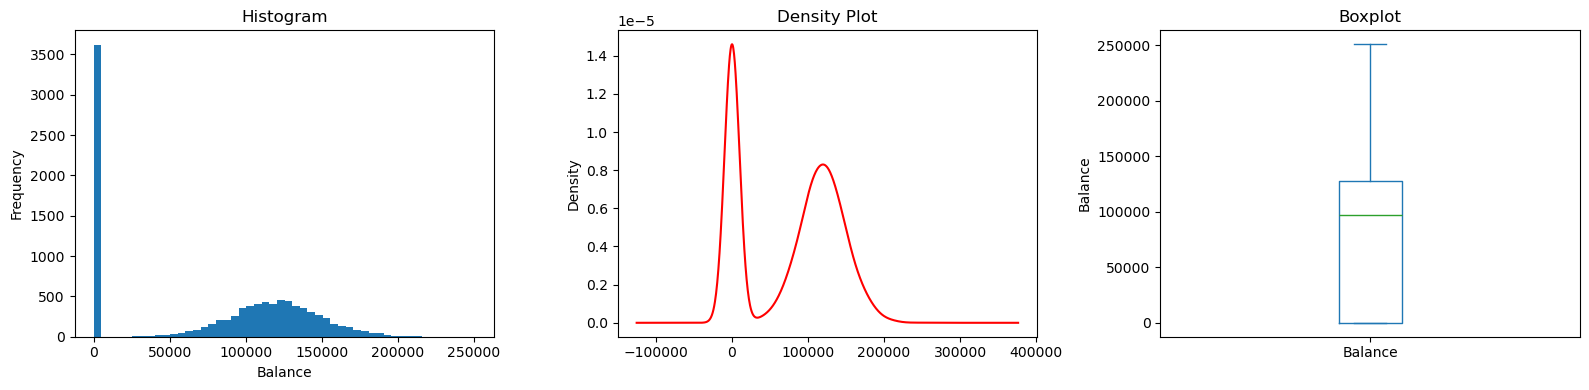

In [16]:
# Plot histogram, density and boxplot for Balance variable
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))
df['Balance'].plot(kind='hist', bins=50, ax=axes[0], xlabel="Balance", title="Histogram")
df['Balance'].plot(kind='density', color='r', ax=axes[1], title='Density Plot')
df['Balance'].plot(kind='box', ax=axes[2], ylabel='Balance', xlabel='', title='Boxplot')
plt.tight_layout()
plt.show()

Boxplots above show some outliers in Age, but they represent real customer data. For example, older customers are genuine cases in a banking dataset, so all outliers are retained for modelling. Balance does not show any outliers but has a large number of customers with zero balance.

### Age and Balance by churn status

The distributions of Age and Balance are compared between customers who stayed and those who churned to check whether these variables could be useful predictors. If the two groups show different distributions, this suggests that the variable carries useful information for predicting churn.

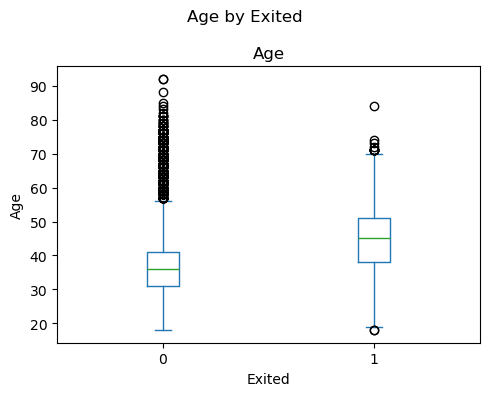

In [17]:
# Boxplot of Age grouped by Exited to compare distributions
df.plot(column="Age", by='Exited', kind='box', subplots=False,
        xlabel='Exited', ylabel="Age",
        title="Age by Exited", figsize=(5, 4))
plt.xlabel('Exited')
plt.tight_layout()
plt.show()

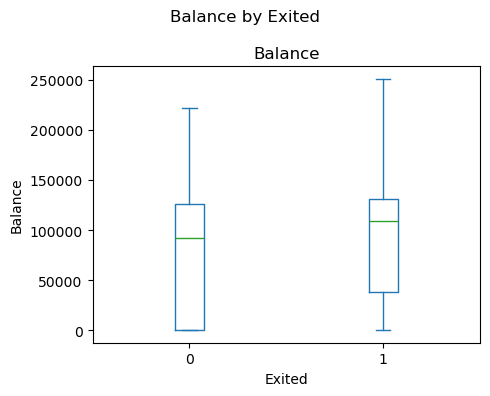

In [18]:
# Boxplot of Balance grouped by Exited to compare distributions
df.plot(column="Balance", by='Exited', kind='box', subplots=False,
        xlabel='Exited', ylabel="Balance",
        title="Balance by Exited", figsize=(5, 4))
plt.xlabel('Exited')
plt.tight_layout()
plt.show()

## 3. Data Preprocessing

### Composite variable: BalanceSalaryRatio

A customer's balance relative to their salary might be more informative than either variable alone. For example, a customer with a high balance but a low salary may behave differently from one with a high balance and a high salary. BalanceSalaryRatio is created by dividing Balance by EstimatedSalary, adding 1 to avoid division by zero.

In [19]:
# Revert to backup copy before creating composite variables
df = df_original.copy()

# Create a composite variable to capture the ratio between balance and salary
# Adding 1 to avoid division by zero
df['BalanceSalaryRatio'] = df['Balance'] / (df['EstimatedSalary'] + 1)
print('New composite feature BalanceSalaryRatio:\n{}'.format(df['BalanceSalaryRatio'].describe()))

New composite feature BalanceSalaryRatio:
count    10000.000000
mean         3.790150
std        100.055758
min          0.000000
25%          0.000000
50%          0.746998
75%          1.514002
max       9770.883148
Name: BalanceSalaryRatio, dtype: float64


### Encoding categorical variables

Geography and Gender are string variables that contain text values. Machine learning algorithms require numerical input, so these variables are converted to integer codes using category codes. The original values are printed before and after conversion to verify the transformation.

In [20]:
# Convert Geography and Gender from string to integer codes for machine learning
print('Geography is originally a string variable:\n{}'.format(df['Geography'].value_counts()))
df['Geography'] = df['Geography'].astype('category').cat.codes
print('\nGeography is converted to integer:\n{}'.format(df['Geography'].value_counts()))

df['Gender'] = df['Gender'].astype('category').cat.codes

print('\nData frame with categorical variables converted to integers:')
df.head()

Geography is originally a string variable:
Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

Geography is converted to integer:
Geography
0    5014
1    2509
2    2477
Name: count, dtype: int64

Data frame with categorical variables converted to integers:


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,BalanceSalaryRatio
0,619,0,0,42,2,0.00,1,1,1,101348.88,1,0.000000
1,608,2,0,41,1,83807.86,1,0,1,112542.58,0,0.744670
2,502,0,0,42,8,159660.80,3,1,0,113931.57,1,1.401362
3,699,0,0,39,1,0.00,2,0,0,93826.63,0,0.000000
4,850,2,0,43,2,125510.82,1,1,1,79084.10,0,1.587035


## 4. Feature Selection

### Correlation between variables

The correlation matrix is used to check whether any features are highly correlated with each other. Highly correlated features carry similar information, so one of them could be dropped. A heatmap is used to visualise the correlation values between all pairs of variables.

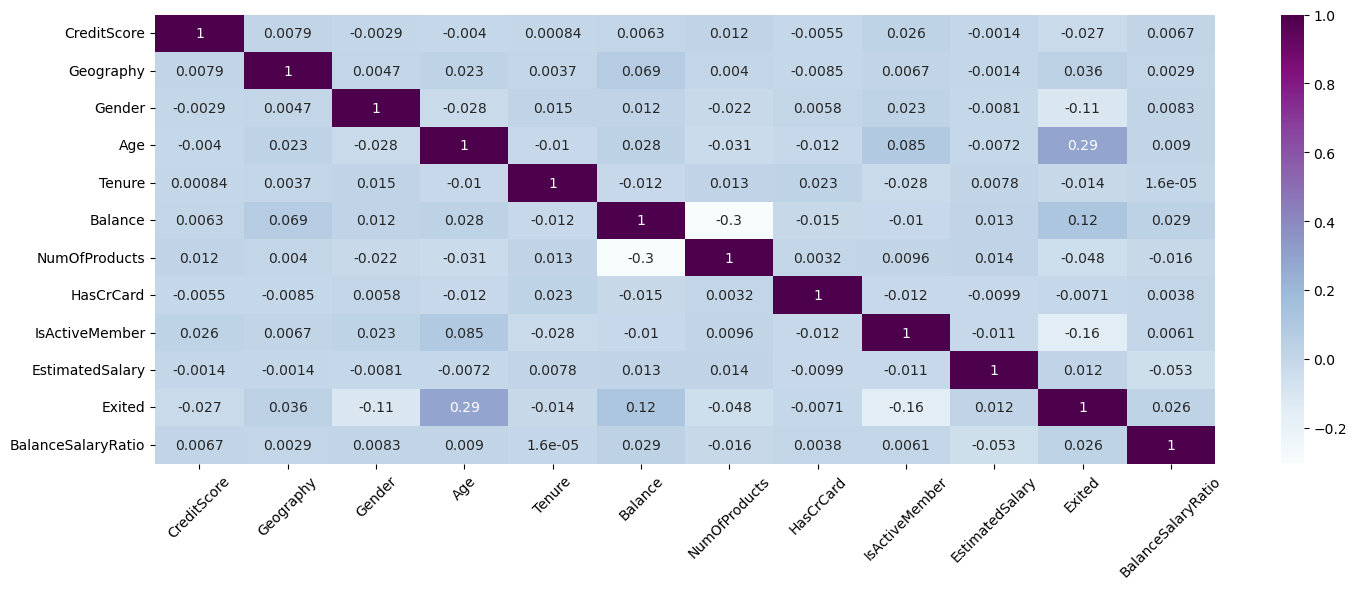

In [21]:
# Compute and visualise the correlation matrix between all variables
corr = df.corr()
plt.figure(figsize=(15, 6))
sns.heatmap(corr, annot=True, cmap="BuPu")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [22]:
# Print correlation values of each feature with the target variable
print('Correlation of each feature with Exited:\n{}'.format(corr['Exited'].sort_values(ascending=False)))

Correlation of each feature with Exited:
Exited                1.000000
Age                   0.285323
Balance               0.118533
Geography             0.035943
BalanceSalaryRatio    0.025963
EstimatedSalary       0.012097
HasCrCard            -0.007138
Tenure               -0.014001
CreditScore          -0.027094
NumOfProducts        -0.047820
Gender               -0.106512
IsActiveMember       -0.156128
Name: Exited, dtype: float64


In [23]:
# Check for high correlation between feature variables (excluding target variable Exited)
corr_features = df.drop('Exited', axis=1).corr()
print('Correlation between features:\n{}'.format(corr_features))
print('\nNo pair of features shows high correlation, so all features are retained')

Correlation between features:
                    CreditScore  Geography    Gender       Age    Tenure  \
CreditScore            1.000000   0.007888 -0.002857 -0.003965  0.000842   
Geography              0.007888   1.000000  0.004719  0.022812  0.003739   
Gender                -0.002857   0.004719  1.000000 -0.027544  0.014733   
Age                   -0.003965   0.022812 -0.027544  1.000000 -0.009997   
Tenure                 0.000842   0.003739  0.014733 -0.009997  1.000000   
Balance                0.006268   0.069408  0.012087  0.028308 -0.012254   
NumOfProducts          0.012238   0.003972 -0.021859 -0.030680  0.013444   
HasCrCard             -0.005458  -0.008523  0.005766 -0.011721  0.022583   
IsActiveMember         0.025651   0.006724  0.022544  0.085472 -0.028362   
EstimatedSalary       -0.001384  -0.001369 -0.008112 -0.007201  0.007784   
BalanceSalaryRatio     0.006691   0.002875  0.008316  0.009047  0.000016   

                     Balance  NumOfProducts  HasCrCard  I

### Feature association with Exited

To measure how strongly each feature is associated with Exited, SelectKBest is applied with three different scoring functions: chi-squared, F-test and mutual information. ExtraTreesClassifier is also used as an alternative approach, which provides feature importance scores while learning a predictive model. Using multiple methods gives more confidence in the results, since no single scoring function works best for every dataset.

In [24]:
# Split dataframe into feature variables X and target variable y
X = df.drop(['Exited'], axis=1)
y = df['Exited']

# Save column names before scaling converts X to array
column_names = X.columns
X.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,BalanceSalaryRatio
0,619,0,0,42,2,0.00,1,1,1,101348.88,0.000000
1,608,2,0,41,1,83807.86,1,0,1,112542.58,0.744670
2,502,0,0,42,8,159660.80,3,1,0,113931.57,1.401362
3,699,0,0,39,1,0.00,2,0,0,93826.63,0.000000
4,850,2,0,43,2,125510.82,1,1,1,79084.10,1.587035


In [25]:
# Apply SelectKBest with chi-squared scoring function
chi2_test = SelectKBest(score_func=chi2, k='all').fit(X, y)
chi2_sorted = pd.Series(data=chi2_test.scores_, index=X.columns).sort_values()

# Repeat with F-test scoring function
ftest = SelectKBest(score_func=f_classif, k='all').fit(X, y)
ftest_sorted = pd.Series(data=ftest.scores_, index=X.columns).sort_values()

# Repeat with mutual information scoring function
mitest = SelectKBest(score_func=mutual_info_classif, k='all').fit(X, y)
mitest_sorted = pd.Series(data=mitest.scores_, index=X.columns).sort_values()

In [26]:
# Use ExtraTreesClassifier as an alternative method to SelectKBest
xtrees = ExtraTreesClassifier().fit(X, y)
xtrees_sorted = pd.Series(data=xtrees.feature_importances_, index=X.columns).sort_values()

In [27]:
# Summary of feature selection results
print('Lowest scoring feature by chi2: {}'.format(chi2_sorted.index[0]))
print('Lowest scoring feature by F-test: {}'.format(ftest_sorted.index[0]))
print('Lowest scoring feature by MI: {}'.format(mitest_sorted.index[0]))
print('Lowest scoring feature by ExtraTrees: {}'.format(xtrees_sorted.index[0]))

Lowest scoring feature by chi2: HasCrCard
Lowest scoring feature by F-test: HasCrCard
Lowest scoring feature by MI: CreditScore
Lowest scoring feature by ExtraTrees: Gender


The strength of association of the feature variables with the target variable is plotted using the four methods. If all methods agree that a feature has low predictive value, it would be a candidate for removal. Since no single feature is consistently ranked as the weakest across all four methods (chi-squared and F-test both rank HasCrCard lowest, but mutual information ranks CreditScore and ExtraTreesClassifier ranks Gender), all 11 features are retained.

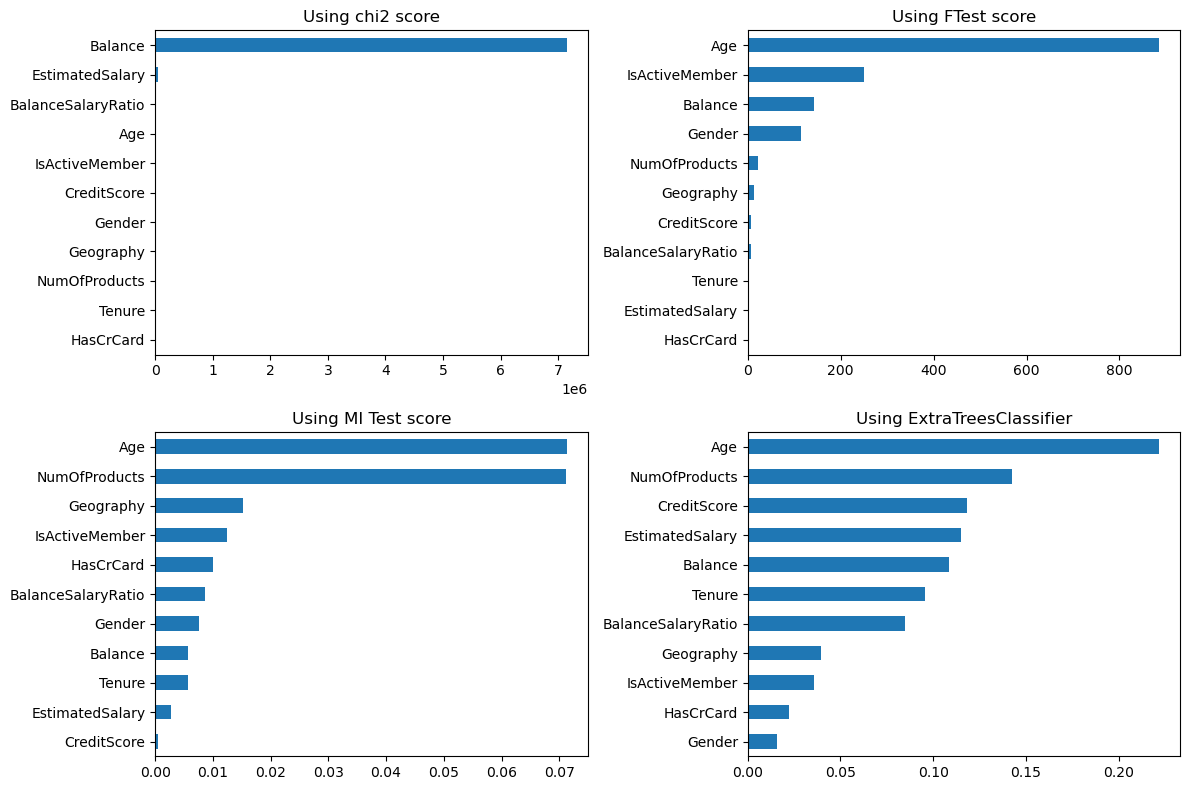

In [28]:
# Plot feature selection scores from all four methods
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 8))
plt.subplots_adjust(wspace=0.6)
chi2_sorted.plot(kind='barh', ax=axes[0, 0], title='Using chi2 score')
ftest_sorted.plot(kind='barh', ax=axes[0, 1], title='Using FTest score')
mitest_sorted.plot(kind='barh', ax=axes[1, 0], title='Using MI Test score')
xtrees_sorted.plot(kind='barh', ax=axes[1, 1], title='Using ExtraTreesClassifier')
plt.tight_layout()
plt.show()

## 5. Model Training and Evaluation

Logistic Regression is a linear classification method that uses a linear decision boundary to separate classes. Decision Tree is a nonlinear method that can capture more complex patterns in the data. Comparing a linear and a nonlinear approach will show which works better for this dataset.

Features are scaled to a 0-1 range using MinMaxScaler. This is primarily important for Logistic Regression, as variables with larger ranges like EstimatedSalary could otherwise dominate weight learning. Decision Trees are not affected by scaling since they use threshold-based splits, but scaling is applied to both models for consistency.
Logistic Regression and Decision Tree are first trained and evaluated as default models using 5-fold cross-validation on training data and accuracy metrics on the test data.

In [29]:
# Scale features to 0-1 range using MinMaxScaler so that variables like EstimatedSalary do not dominate the learning
scaler = MinMaxScaler()
scaler.fit(X)
X = scaler.transform(X)

In [30]:
# Train and evaluate a model with cross-validation and a separate test set
def train_and_evaluate(model, X, y):

    print('\nResults from algorithm {}:'.format(model))

    # Split data into train and test sets
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Cross-validation accuracy on the training data
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
    print('Mean cross-validation accuracy is {:.3f} with SD {:.3f}'
          .format(np.mean(scores), np.std(scores)))

    # Fit the model on the full training data
    learnt_model = model.fit(X_train, y_train)
    print('\nAccuracy on training data is {:.3f}\n'.format(model.score(X_train, y_train)))

    # Predict the test data and print the test metrics
    y_pred = model.predict(X_test)
    print('Test data metrics: accuracy={:.3f}, f1={:.3f}, precision={:.3f}, recall={:.3f}'
          .format(accuracy_score(y_true=y_test, y_pred=y_pred),
                  f1_score(y_true=y_test, y_pred=y_pred),
                  precision_score(y_true=y_test, y_pred=y_pred),
                  recall_score(y_true=y_test, y_pred=y_pred)))

    # Plot the confusion matrix
    cm = confusion_matrix(y_true=y_test, y_pred=y_pred)
    plt.figure(figsize=(2, 2))
    ax = sns.heatmap(cm, annot=True,  fmt='d', cbar=False, xticklabels=['0', '1'],
                 yticklabels=['0', '1'], square=True,
                 linewidths=8.0)
    ax.set_xlabel('Predicted Exited')
    ax.set_ylabel('Actual Exited')
    plt.tight_layout()
    plt.show()

    return learnt_model


Results from algorithm LogisticRegression(max_iter=200):
Mean cross-validation accuracy is 0.807 with SD 0.006

Accuracy on training data is 0.809

Test data metrics: accuracy=0.816, f1=0.267, precision=0.615, recall=0.170


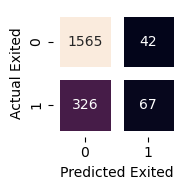

In [31]:
# Train and evaluate Logistic Regression on the dataset
_ = train_and_evaluate(LogisticRegression(max_iter=200), X, y)


Results from algorithm DecisionTreeClassifier():
Mean cross-validation accuracy is 0.794 with SD 0.010

Accuracy on training data is 1.000

Test data metrics: accuracy=0.789, f1=0.482, precision=0.466, recall=0.499


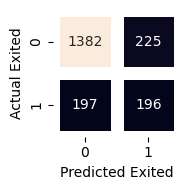

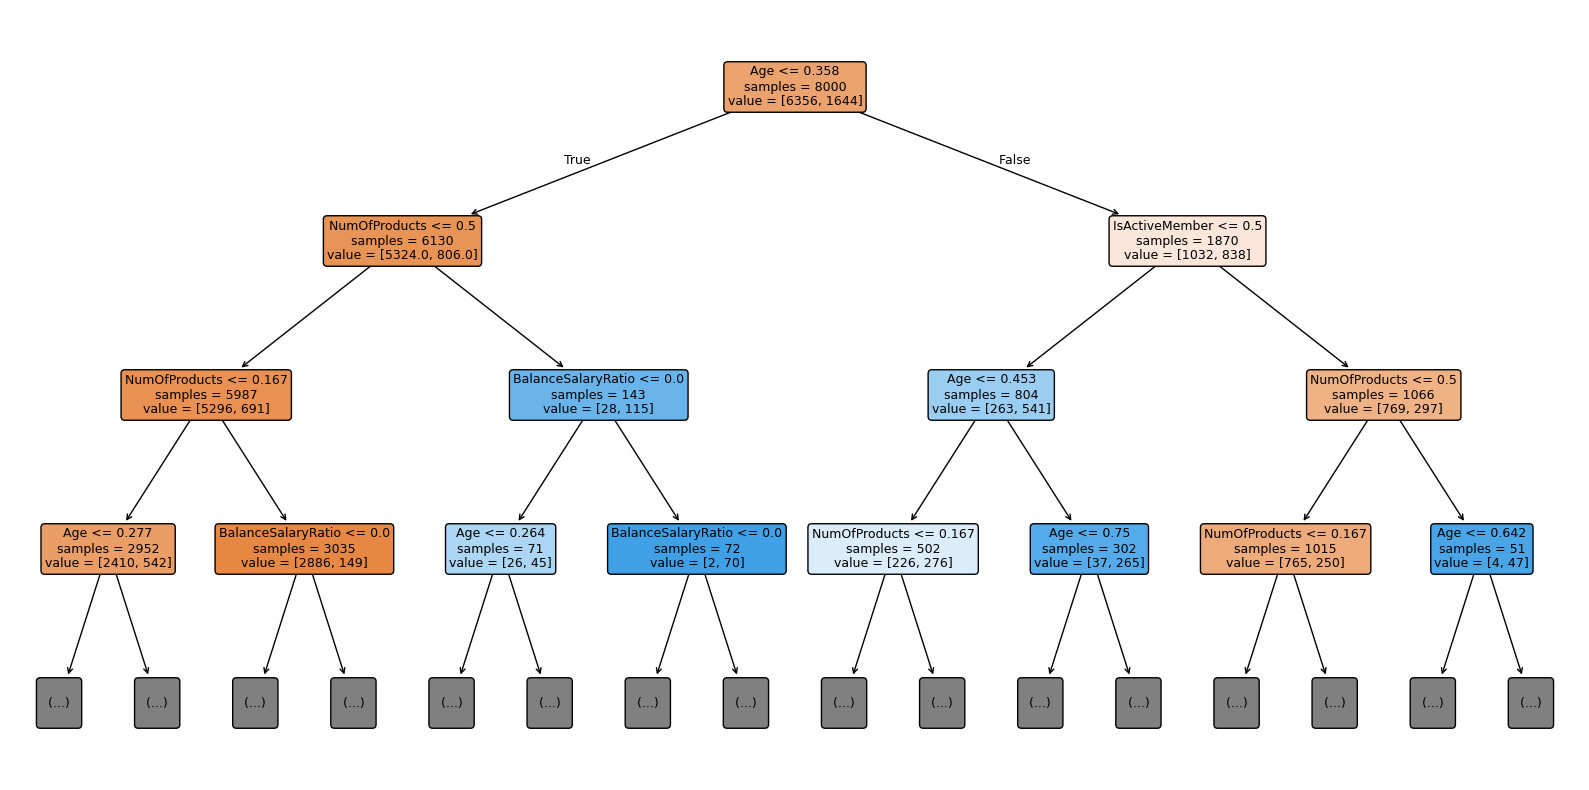

In [32]:
# Train and evaluate Decision Tree and visualise the top levels of the tree
learnt_model = train_and_evaluate(DecisionTreeClassifier(), X, y)
plt.figure(figsize=(16, 8))
plot_tree(learnt_model, max_depth=3, feature_names=list(column_names),
          fontsize=9, filled=True, impurity=False, rounded=True)
plt.tight_layout()
plt.show()

Logistic Regression achieves higher test accuracy of 0.816 but has very low recall of 0.170, meaning it misses most churned customers. Decision Tree achieves a lower test accuracy of 0.789 but a much higher recall of 0.499. Decision Tree shows signs of overfitting with training accuracy of 1.000 compared to much lower test accuracy. Hyperparameter tuning in the next section aims to reduce overfitting and improve performance.

## 6. Hyperparameter Tuning with Cross-Validation

Best hyperparameters are selected using 10-fold cross-validation on the training data, and accuracy is reported using the test dataset which was not used to select the hyperparameter.

* For Logistic Regression the regularisation strength C is varied, where lower values mean stronger regularisation.
* For Decision Tree max_depth is varied to control how deep the tree can grow and reduce overfitting.

In [33]:
# Return the mean 10-fold cross-validation accuracy and the trained model
def train_model(algorithm, hyperparams, X, y):
    model = algorithm(**hyperparams)
    scores = cross_val_score(model, X, y, cv=10, scoring='accuracy')
    learnt_model = model.fit(X, y)
    return (np.mean(scores), learnt_model)


# Split data into training and test sets for hyperparameter tuning
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

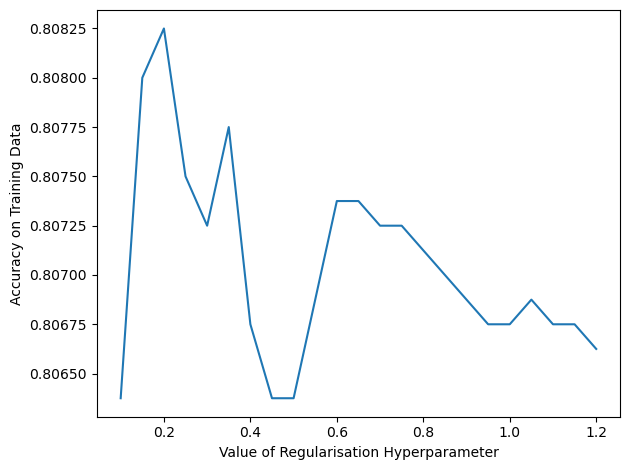

In [34]:
# Try a range of regularisation strengths for Logistic Regression
reg_values = [0.05 * i for i in range(2, 25)]
reg_accuracy = []
for reg_strength in reg_values:
    acc, _ = train_model(LogisticRegression, {'C': reg_strength, 'max_iter': 200}, X_train, y_train)
    reg_accuracy.append(acc)

# Plot the results
plt.plot(reg_values, reg_accuracy)
plt.ylabel('Accuracy on Training Data')
plt.xlabel('Value of Regularisation Hyperparameter')
plt.tight_layout()
plt.show()

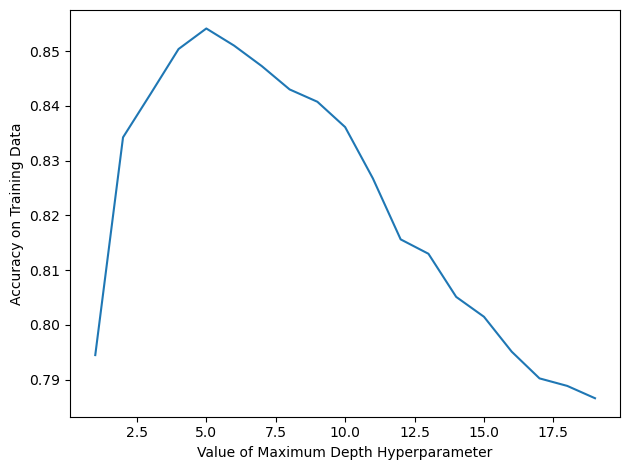

In [35]:
# Try a range of maximum depth values for Decision Tree
depth_values = [i for i in range(1, 20)]
depth_accuracy = []
for depth in depth_values:
    acc, _ = train_model(DecisionTreeClassifier, {'max_depth': depth}, X_train, y_train)
    depth_accuracy.append(acc)

# Plot the results
plt.plot(depth_values, depth_accuracy)
plt.ylabel('Accuracy on Training Data')
plt.xlabel('Value of Maximum Depth Hyperparameter')
plt.tight_layout()
plt.show()

The regularisation plot shows that accuracy is relatively stable across different C values. The depth plot shows that accuracy increases with depth, peaks around depth 5, and then decreases as deeper trees begin to overfit. Each model is trained with its best hyperparameter value and evaluated on the test set using accuracy, F1 score, precision and recall. The confusion matrix is included because with an imbalanced target variable like Exited, it shows exactly how many churned customers were missed by the model.

Best C value: 0.20
Test data metrics: accuracy=0.808, f1=0.194, precision=0.561, recall=0.117


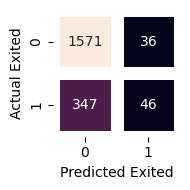

In [36]:
# Train Logistic Regression with the best C value
best_C = reg_values[np.argmax(reg_accuracy)]
print('Best C value: {:.2f}'.format(best_C))

train_accuracy, best_lr = train_model(LogisticRegression, {'C': best_C, 'max_iter': 200}, X_train, y_train)

# Calculate the test set metrics
y_pred = best_lr.predict(X_test)
lr_test_accuracy = accuracy_score(y_true=y_test, y_pred=y_pred)
lr_f1 = f1_score(y_true=y_test, y_pred=y_pred)
lr_precision = precision_score(y_true=y_test, y_pred=y_pred)
lr_recall = recall_score(y_true=y_test, y_pred=y_pred)

print('Test data metrics: accuracy={:.3f}, f1={:.3f}, precision={:.3f}, recall={:.3f}'
      .format(lr_test_accuracy, lr_f1, lr_precision, lr_recall))

# Plot the confusion matrix
cm = confusion_matrix(y_true=y_test, y_pred=y_pred)
plt.figure(figsize=(2, 2))
ax = sns.heatmap(cm, annot=True, fmt='d', cbar=False, xticklabels=['0', '1'],
                 yticklabels=['0', '1'], square=True,
                 linewidths=8.0)
ax.set_xlabel('Predicted Exited')
ax.set_ylabel('Actual Exited')
plt.tight_layout()
plt.show()

Best max_depth value: 5
Test data metrics: accuracy=0.857, f1=0.518, precision=0.762, recall=0.392


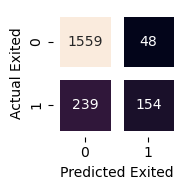

In [37]:
# Train Decision Tree with the best max_depth value
best_depth = depth_values[np.argmax(depth_accuracy)]
print('Best max_depth value: {}'.format(best_depth))

train_accuracy, best_dt = train_model(DecisionTreeClassifier, {'max_depth': best_depth}, X_train, y_train)

# Calculate the test set metrics
y_pred = best_dt.predict(X_test)
dt_test_accuracy = accuracy_score(y_true=y_test, y_pred=y_pred)
dt_f1 = f1_score(y_true=y_test, y_pred=y_pred)
dt_precision = precision_score(y_true=y_test, y_pred=y_pred)
dt_recall = recall_score(y_true=y_test, y_pred=y_pred)

print('Test data metrics: accuracy={:.3f}, f1={:.3f}, precision={:.3f}, recall={:.3f}'
      .format(dt_test_accuracy, dt_f1, dt_precision, dt_recall))

# Plot the confusion matrix
cm = confusion_matrix(y_true=y_test, y_pred=y_pred)
plt.figure(figsize=(2, 2))
ax = sns.heatmap(cm, annot=True, fmt='d', cbar=False, xticklabels=['0', '1'],
                 yticklabels=['0', '1'], square=True,
                 linewidths=8.0)
ax.set_xlabel('Predicted Exited')
ax.set_ylabel('Actual Exited')
plt.tight_layout()
plt.show()

## 7. Model Comparison and Overfitting Check

Both models have now been tuned with their best hyperparameter values. Training and test accuracy are compared to check whether the tuned models are overfitting. If training accuracy is much higher than test accuracy, the model has memorised the training data rather than learning general patterns. All test metrics for both tuned models are then compared in a summary table to determine which model performs better on this churn prediction task.

In [38]:
# Check accuracy on training data for tuned models to assess overfitting
lr_train_acc = best_lr.score(X_train, y_train)
dt_train_acc = best_dt.score(X_train, y_train)

print('Logistic Regression - Training: {:.3f}, Test: {:.3f}, Difference: {:.3f}'
      .format(lr_train_acc, lr_test_accuracy, lr_train_acc - lr_test_accuracy))
print('Decision Tree - Training: {:.3f}, Test: {:.3f}, Difference: {:.3f}'
      .format(dt_train_acc, dt_test_accuracy, dt_train_acc - dt_test_accuracy))

Logistic Regression - Training: 0.809, Test: 0.808, Difference: 0.000
Decision Tree - Training: 0.859, Test: 0.857, Difference: 0.002


In [39]:
# Compare test data metrics for both tuned models to determine which performs better on churn prediction
comparison = pd.DataFrame({
    'Logistic Regression': [lr_test_accuracy, lr_f1, lr_precision, lr_recall],
    'Decision Tree': [dt_test_accuracy, dt_f1, dt_precision, dt_recall]
}, index=['Accuracy', 'F1 Score', 'Precision', 'Recall'])

print('Model comparison on test data:\n{}'.format(comparison))

Model comparison on test data:
           Logistic Regression  Decision Tree
Accuracy              0.808500       0.856500
F1 Score              0.193684       0.517647
Precision             0.560976       0.762376
Recall                0.117048       0.391858


Decision Tree with max_depth=5 outperforms Logistic Regression (C=0.20) across all test metrics including accuracy, F1 score, precision and recall. The default Decision Tree had a training accuracy of 1.000 with much lower test accuracy, indicating severe overfitting. After tuning max_depth to 5, the training-test difference dropped close to zero, confirming that overfitting has been effectively resolved. Logistic Regression shows minimal overfitting but struggles to identify churned customers due to the imbalanced target variable. Decision Tree catches more churned customers, making it the better model for this churn prediction task.